# 02 — Football dataset preparation

**Goal:** inspect the full YOLO dataset before fine-tuning. Raw files remain unchanged.

This notebook calls reusable validation code and presents the results. It does not train a model or change splits. Results are generated locally, no conclusions about the actual dataset have been pre-filled.

Expected layout: `data/raw/football-image-dataset/{images,labels}/{train,val}` plus the source `data.yaml` (or `data.yml`). Use the project `.venv` kernel. Existing dependencies: Pillow, PyYAML, Matplotlib, IPython.

Source: https://github.com/skaczylo/Football-Image-Dataset


## 1. Locate the project and load parameters

In [20]:
from pathlib import Path
from collections import Counter
from IPython.display import display, HTML
import html
import json
import random
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'configs/dataset_preparation.yaml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project containing configs/dataset_preparation.yaml')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sports_analyzer.dataset_preparation import audit_dataset, save_audit

CONFIG_PATH = ROOT / 'configs/dataset_preparation.yaml'
config = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
DATASET = ROOT / config['dataset_root']
METADATA = DATASET / config['dataset_yaml']
if not METADATA.is_file():
    raise FileNotFoundError(f'{METADATA}: check dataset_yaml in {CONFIG_PATH}; perhaps the file is named data.yml')
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
COLORS = {'ball': '#D55E00', 'player': '#0072B2', 'referee': '#009E73'}

def table(rows, limit=15):
    if not rows:
        print('No rows.')
        return
    keys = list(rows[0])
    header = ''.join(f'<th>{html.escape(str(k))}</th>' for k in keys)
    body = ''.join('<tr>' + ''.join(f'<td>{html.escape(str(row.get(k, "")))}</td>' for k in keys) + '</tr>'
                   for row in rows[:limit])
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))
    print(f'Showing {min(limit, len(rows))} of {len(rows)} rows')

print('Dataset:', DATASET)
print('Classes:', config['expected_names'])

Dataset: C:\Users\johan\PycharmProjects\HSLU\DSPRO2\dspro2-sports-analyzer\data\raw\football-image-dataset
Classes: ['ball', 'player', 'referee']


## 2. Audit and save reports

Checks every annotation row, not just a sample. Invalid rows are excluded from box statistics but retained in the issue report. Therefore those statistics are provisional if errors exist.

Missing labels are errors, empty label files may represent valid negative images. A small box is a review item, not a reason to delete a ball annotation. Exact duplicates are checked by bytes and decoded RGB pixels. A 64-bit difference hash finds **possible** visually similar pairs, with false positives and false negatives. Pairwise comparison is suitable for 612 images, larger datasets need an indexed search.

In [21]:
audit = audit_dataset(
    DATASET, METADATA, config['expected_names'],
    tiny_side_pixels=config['tiny_side_pixels'],
    near_duplicate_distance=config['near_duplicate_distance'],
)
REPORT = save_audit(audit, ROOT / config['output'])
(REPORT / 'config.yaml').write_text(CONFIG_PATH.read_text(encoding='utf-8'), encoding='utf-8')
print(json.dumps(audit['summary'], indent=2))
print('Reports:', REPORT)
table([{'severity': severity, 'code': kind, 'count': count}
       for (severity, kind), count in sorted(Counter((r['severity'], r['code']) for r in audit['issues']).items())])

{
  "images": 612,
  "boxes": 10136,
  "images_by_split": {
    "train": 512,
    "val": 100
  },
  "errors": 0,
  "warnings": 31,
  "cross_split_exact_pairs": 0,
  "cross_split_visual_candidates": 0
}
Reports: C:\Users\johan\PycharmProjects\HSLU\DSPRO2\dspro2-sports-analyzer\outputs\dataset_preparation\20261020T185611109011Z


severity,code,count
warning,empty_label,1
warning,rounding_overflow,19
warning,tiny_box,11


Showing 3 of 3 rows


In [22]:
# Complete details are in issues.csv; this preview is intentionally bounded.
table(sorted(audit['issues'], key=lambda r: (r['severity'] != 'error', r['path'], r['line'] or 0)), limit=20)
table([{'split': split,
        'images': sum(r['split'] == split for r in audit['images']),
        'images_with_errors': sum(r['split'] == split and r['status'] != 'ok' for r in audit['images']),
        'valid_boxes': sum(r['split'] == split for r in audit['boxes'])}
       for split in ('train', 'val')])

severity,code,path,line,detail
warning,tiny_box,labels/train/20250710_144746_004987.txt,17,"Box 3.75 x 45.92 px; inspect, do not auto-delete"
warning,rounding_overflow,labels/train/20250710_144746_058cde.txt,9,Boundary overflow <= 1e-6; coordinates unchanged
warning,rounding_overflow,labels/train/20250710_144746_0c5785.txt,3,Boundary overflow <= 1e-6; coordinates unchanged
warning,tiny_box,labels/train/20250710_144746_0c5785.txt,17,"Box 8.46 x 2.12 px; inspect, do not auto-delete"
warning,rounding_overflow,labels/train/20250710_144746_0f4681.txt,11,Boundary overflow <= 1e-6; coordinates unchanged
warning,tiny_box,labels/train/20250710_144746_1209a0.txt,19,"Box 1.19 x 0.40 px; inspect, do not auto-delete"
warning,rounding_overflow,labels/train/20250710_144746_16e0f7.txt,16,Boundary overflow <= 1e-6; coordinates unchanged
warning,rounding_overflow,labels/train/20250710_144746_173c2e.txt,11,Boundary overflow <= 1e-6; coordinates unchanged
warning,rounding_overflow,labels/train/20250710_144746_19dab9.txt,9,Boundary overflow <= 1e-6; coordinates unchanged
warning,rounding_overflow,labels/train/20250710_144746_1c995e.txt,12,Boundary overflow <= 1e-6; coordinates unchanged


Showing 20 of 31 rows


split,images,images_with_errors,valid_boxes
train,512,0,8329
val,100,0,1807


Showing 2 of 2 rows


## 3. Class balance and object sizes

Compare both the absolute annotation counts and the proportion of images containing each class. Image proportions need not sum to 100% because an image can contain multiple classes. Tiny objects can be valid, ball detection is particularly sensitive to resizing.

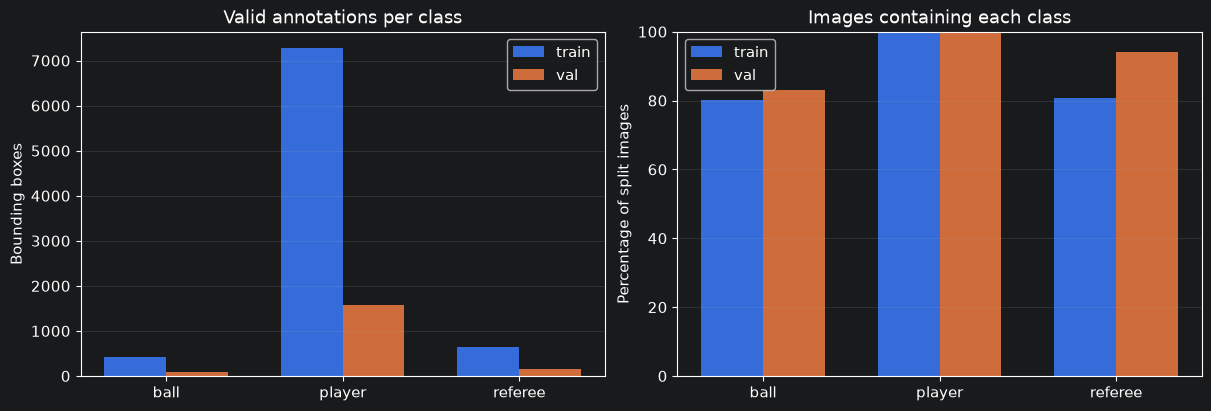

In [23]:
classes = config['expected_names']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for offset, split in enumerate(('train', 'val')):
    counts = Counter(b['label'] for b in audit['boxes'] if b['split'] == split)
    denominator = sum(r['split'] == split for r in audit['images'])
    presence = {name: len({b['image'] for b in audit['boxes'] if b['split'] == split and b['label'] == name})
                for name in classes}
    positions = [i + (offset-0.5)*0.35 for i in range(len(classes))]
    axes[0].bar(positions, [counts[name] for name in classes], width=0.35, label=split)
    axes[1].bar(positions, [100*presence[name]/denominator if denominator else 0 for name in classes],
                width=0.35, label=split)
for ax in axes:
    ax.set_xticks(range(len(classes)), classes)
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
axes[0].set(title='Valid annotations per class', ylabel='Bounding boxes')
axes[1].set(title='Images containing each class', ylabel='Percentage of split images', ylim=(0, 100))
plt.show()

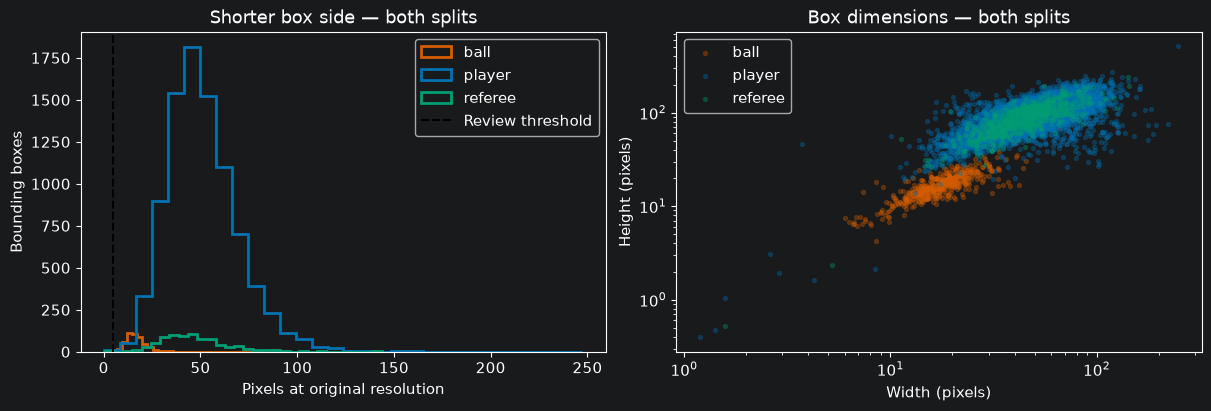

width,height,mode,images
1920,1080,RGB,548
1280,720,RGB,44
854,480,RGB,3
640,360,RGB,17


Showing 4 of 4 rows


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for name in classes:
    group = [b for b in audit['boxes'] if b['label'] == name]
    if group:
        axes[0].hist([min(b['width_pixels'], b['height_pixels']) for b in group],
                     bins=30, histtype='step', linewidth=2, label=name, color=COLORS.get(name))
        axes[1].scatter([b['width_pixels'] for b in group], [b['height_pixels'] for b in group],
                        s=8, alpha=0.3, label=name, color=COLORS.get(name))
axes[0].axvline(config['tiny_side_pixels'], color='black', linestyle='--', label='Review threshold')
axes[0].set(title='Shorter box side — both splits', xlabel='Pixels at original resolution', ylabel='Bounding boxes')
axes[1].set(title='Box dimensions — both splits', xlabel='Width (pixels)', ylabel='Height (pixels)', xscale='log', yscale='log')
for ax in axes:
    ax.legend()
plt.show()
table([{'width': w, 'height': h, 'mode': mode, 'images': count}
       for (w, h, mode), count in Counter((r['width'], r['height'], r['mode'])
                                        for r in audit['images'] if r['width']).items()])

## 4. Ground-truth overlays

A fixed seed makes the sample repeatable. Check missed annotations, class confusion, tightness and objects outside the pitch. Inspect unusual boxes separately, random sampling alone will not reliably expose them.

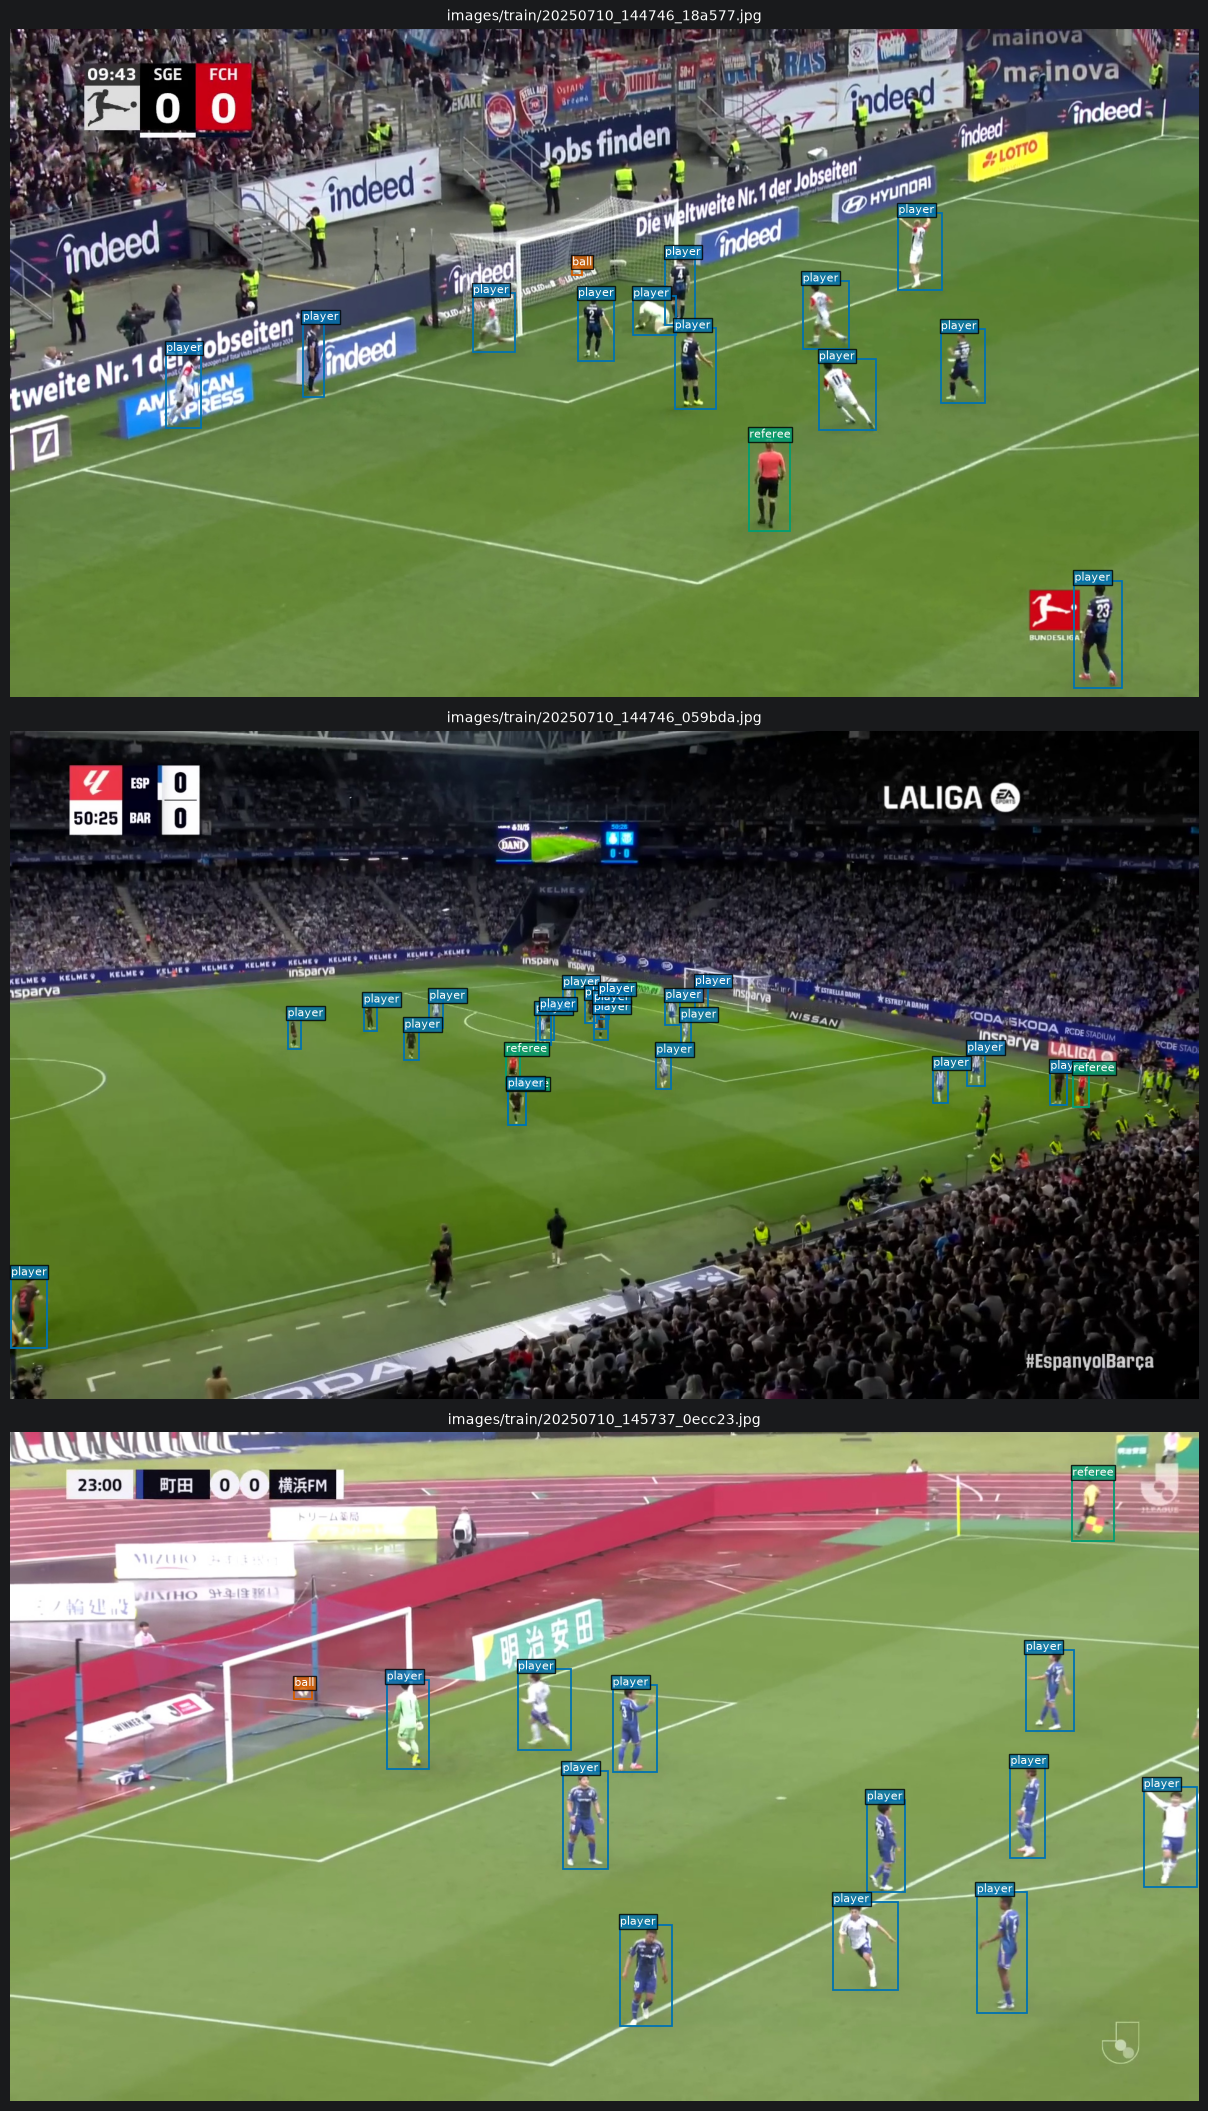

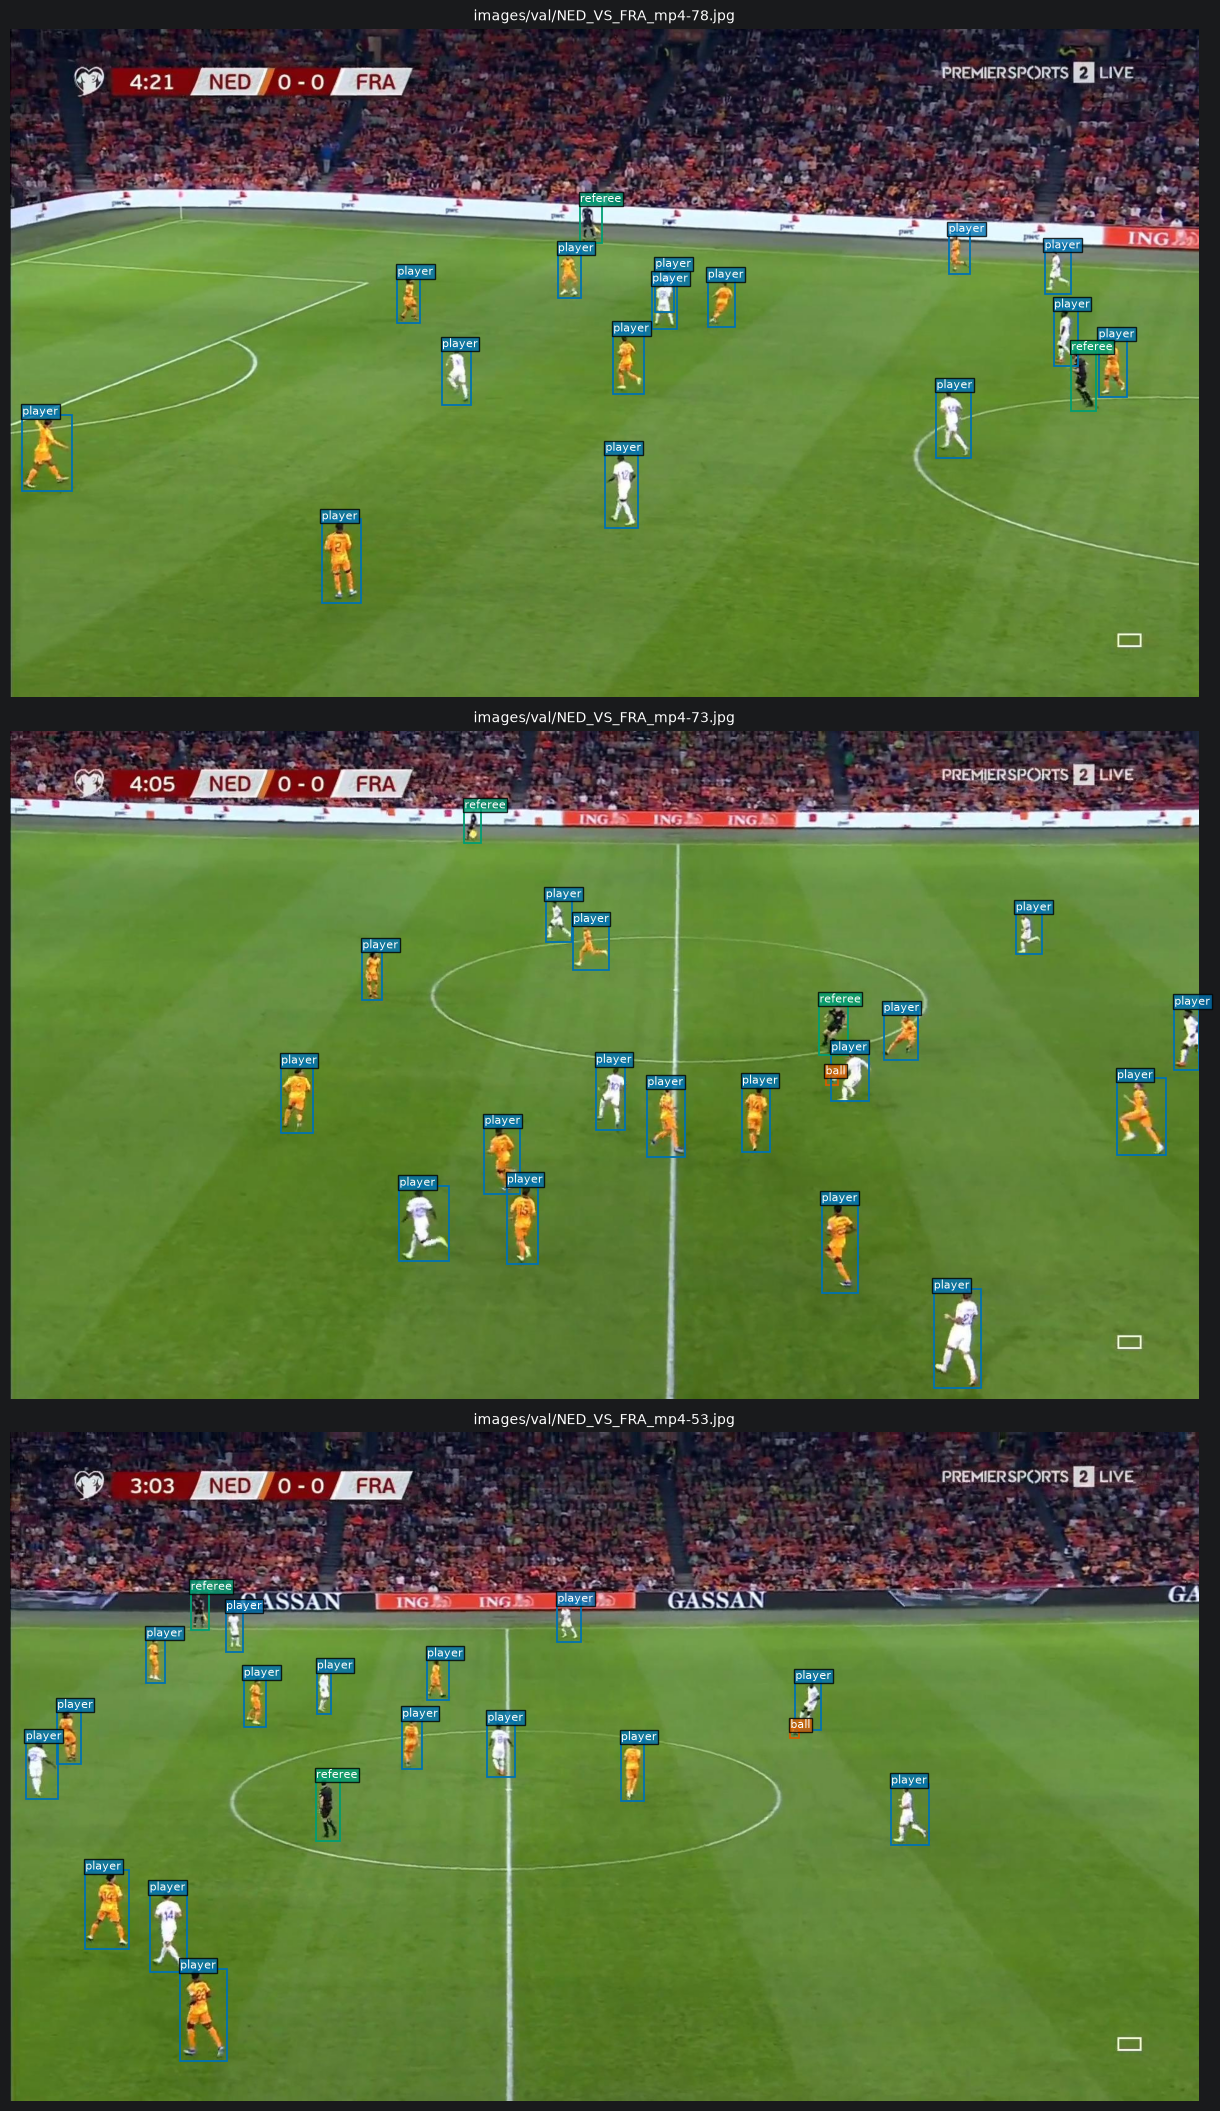

In [25]:
def show_images(relative_paths):
    fig, axes = plt.subplots(len(relative_paths), 1, figsize=(14, 7*len(relative_paths)), squeeze=False,
                             layout='constrained')
    for ax, relative in zip(axes.flat, relative_paths):
        with Image.open(DATASET / relative) as image:
            ax.imshow(image.convert('RGB'))
        for b in audit['boxes']:
            if b['image'] != relative:
                continue
            color = COLORS.get(b['label'], 'purple')
            ax.add_patch(Rectangle((b['x1'], b['y1']), b['x2']-b['x1'], b['y2']-b['y1'],
                                   fill=False, edgecolor=color, linewidth=1.3))
            ax.text(b['x1'], b['y1'], b['label'], fontsize=8, color='white',
                    bbox={'facecolor': color, 'alpha': 0.8, 'pad': 1})
        ax.set_title(relative, fontsize=10)
        ax.axis('off')
    plt.show()

rng = random.Random(config['seed'])
for split in ('train', 'val'):
    candidates = [r['image'] for r in audit['images'] if r['split'] == split and r['dhash'] is not None]
    chosen = rng.sample(candidates, min(config['samples_per_split'], len(candidates)))
    if chosen:
        show_images(chosen)

In [26]:
smallest = sorted(audit['boxes'], key=lambda b: min(b['width_pixels'], b['height_pixels']))[:10]
table([{k: b[k] for k in ('image', 'line', 'label', 'width_pixels', 'height_pixels')} for b in smallest])
# To inspect one image directly, use its relative path from the table:
# show_images(['images/train/your_image.jpg'])

image,line,label,width_pixels,height_pixels
images/train/20250710_144746_1209a0.jpg,19,player,1.1924434157256656,0.39748113857521616
images/train/20250710_144746_23915c.jpg,13,player,1.408324166670991,0.46944138889018633
images/train/20250710_144746_33cabf.jpg,21,referee,1.5871421863309478,0.5290473954436749
images/train/20250710_144746_2acefd.jpg,19,player,1.5773320846165888,1.0515547230777713
images/train/20250710_144746_38cf4b.jpg,18,player,4.270458513617768,1.6424840436992099
images/train/20250710_144746_3329d6.jpg,17,player,2.8857130660559958,1.9238087107040003
images/train/20250710_144746_0c5785.jpg,17,player,8.46475832709757,2.1161895817744694
images/train/20250710_144746_35f86b.jpg,15,referee,5.237569214891527,2.3278085399519854
images/train/20250710_144746_34ed63.jpg,13,player,2.6233755145964097,3.0606047670290875
images/train/20250710_144746_004987.jpg,17,player,3.748958931678044,45.92474691305441


Showing 10 of 10 rows


11 kleine Bounding Boxes zur Sichtprüfung


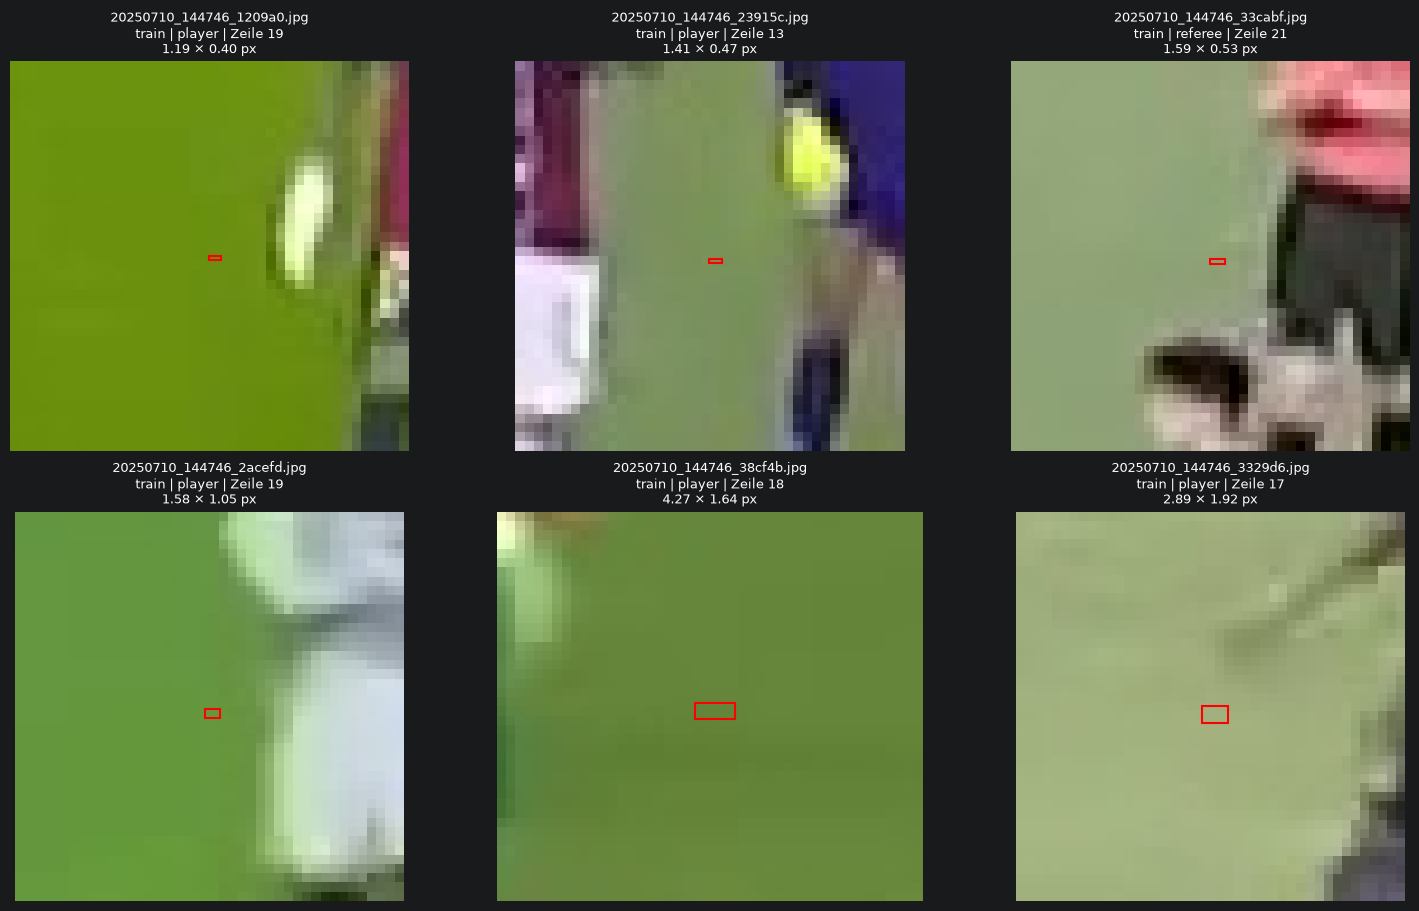

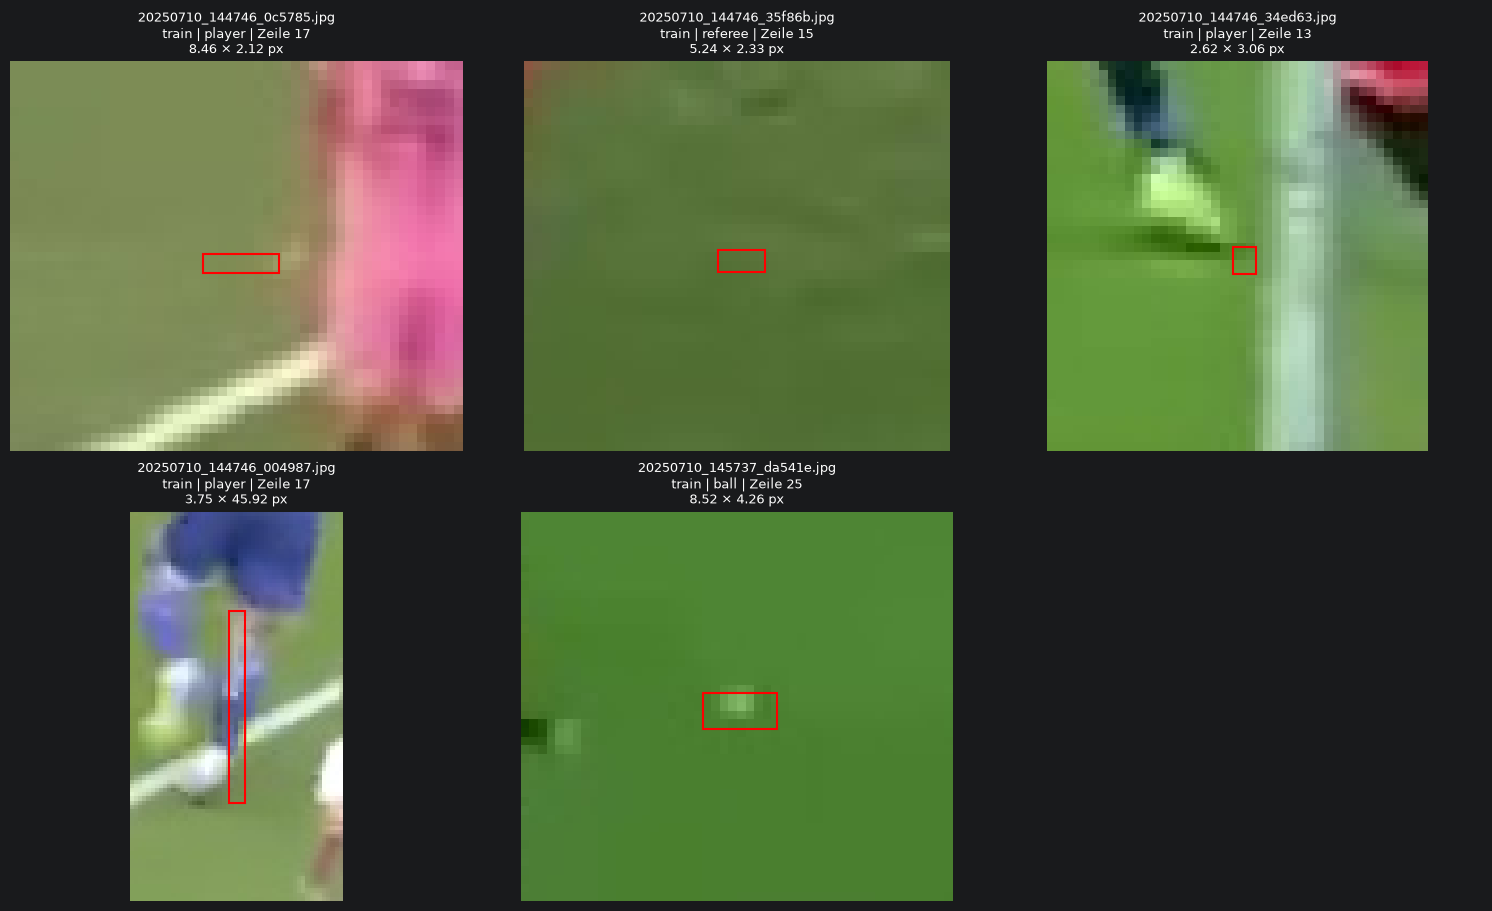

In [27]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

tiny_boxes = sorted(
    (
        box
        for box in audit["boxes"]
        if min(box["width_pixels"], box["height_pixels"])
        < config["tiny_side_pixels"]
    ),
    key=lambda box: min(box["width_pixels"], box["height_pixels"]),
)

print(f"{len(tiny_boxes)} kleine Bounding Boxes zur Sichtprüfung")

page_size = 6

for start in range(0, len(tiny_boxes), page_size):
    batch = tiny_boxes[start:start + page_size]
    rows = math.ceil(len(batch) / 3)

    fig, axes = plt.subplots(
        rows,
        3,
        figsize=(15, rows * 4.5),
        squeeze=False,
        layout="constrained",
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, box in zip(axes.flat, batch):
        image_path = DATASET / box["image"]

        if not image_path.is_file():
            raise FileNotFoundError(f"Bild fehlt: {image_path}")

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        # Kontext erhalten und auch sehr kleine Objekte sichtbar machen.
        padding = max(
            20,
            math.ceil(max(box["width_pixels"], box["height_pixels"]) / 2),
        )
        left = max(0, math.floor(box["x1"]) - padding)
        top = max(0, math.floor(box["y1"]) - padding)
        right = min(image.width, math.ceil(box["x2"]) + padding)
        bottom = min(image.height, math.ceil(box["y2"]) + padding)

        if right <= left or bottom <= top:
            raise ValueError(
                f"Ungültiger Ausschnitt: {image_path}, Zeile {box['line']}"
            )

        ax.imshow(
            image.crop((left, top, right, bottom)),
            interpolation="nearest",
        )
        ax.add_patch(
            Rectangle(
                (box["x1"] - left, box["y1"] - top),
                box["width_pixels"],
                box["height_pixels"],
                fill=False,
                edgecolor="red",
                linewidth=1.5,
            )
        )
        ax.set_title(
            f"{Path(box['image']).name}\n"
            f"{box['split']} | {box['label']} | Zeile {box['line']}\n"
            f"{box['width_pixels']:.2f} × "
            f"{box['height_pixels']:.2f} px",
            fontsize=9,
        )

    plt.show()

Visual inspection of the small-box warnings revealed several apparently incorrect annotations, one candidate may represent a football. No annotations were modified. Annotation review and corrections are deferred to dataset preparation before fine-tuning.

## 5. Split overlap and visual duplicate candidates

Exact cross-split duplicates prevent an independent comparison. Visual candidates require review. Neither a clean hash result nor the source split proves match-level independence: different frames from the same sequence can still leak context. Resolve match/sequence provenance before claiming generalization to unseen games. Do not infer a match ID solely from an unexplained filename prefix.

In [28]:
cross_split = sorted([d for d in audit['duplicates'] if d['cross_split']],
                     key=lambda d: (d['kind'] == 'visual_candidate', d['dhash_distance']))
table(cross_split, limit=15)
if cross_split:
    first = cross_split[0]
    print('First candidate:', first['kind'], '| dHash distance:', first['dhash_distance'])
    show_images([first['image_a'], first['image_b']])
else:
    print('No cross-split candidates found by these checks. Sequence independence remains unverified.')

No rows.
No cross-split candidates found by these checks. Sequence independence remains unverified.


## 6. Decision before training

Record findings below after execution. Technical errors must be resolved deliberately before training, never silently drop rows or clamp boxes. Review warnings and duplicate candidates.

- Annotation issues and decisions:
- Cross-split candidate review:
- Match/sequence provenance and split decision:
- Known limitations:

In [30]:
summary = audit['summary']
if summary['errors']:
    print(f"BLOCKED: {summary['errors']} technical errors; inspect {REPORT / 'issues.csv'}")
elif summary['cross_split_exact_pairs']:
    print('BLOCKED: exact duplicates across train/val; resolve the split before evaluation.')
else:
    print('Technical checks passed. Review warnings, visual candidates and split provenance before training.')
print('Raw images and labels have not been changed.')

Technical checks passed. Review warnings, visual candidates and split provenance before training.
Raw images and labels have not been changed.
